# Detecção de anomalias: o que acontece diante de ataques nunca vistos

Este notebook responde à pergunta central do projeto: **quanto um modelo supervisionado perde
diante de ataques que nunca viu, e quanto disso um detector de anomalias recupera, a que custo em
falsos positivos?**

O protocolo é o P2 ([ADR 0002](../docs/adr/0002-protocolos-de-divisao.md)): treino e validação de
segunda a quarta (tráfego normal, força bruta, DoS e Heartbleed), teste na quinta e na sexta (ataques
web, Infiltration, Bot, PortScan e DDoS). **Nenhuma família do teste aparece no treino.** Quatro
modelos são comparados:

| Modelo | Treino | Papel |
|---|---|---|
| XGBoost · P1 | Divisão temporal: já viu todas as famílias | Teto: o que se consegue conhecendo o ataque |
| XGBoost · P2 | Normal + força bruta + DoS | Supervisionado diante do desconhecido |
| Isolation Forest · P2 | Só o tráfego normal | Anomalia, clássico |
| Autoencoder · P2 | Só o tráfego normal | Anomalia, rede neural ([ADR 0007](../docs/adr/0007-autoencoder-no-scikit-learn.md)) |

Todos viram detectores com o mesmo ponto de operação: o limiar que dá **1 % de falsos positivos
nos fluxos normais da validação**, fixado antes de olhar o teste. No XGBoost, o score é
1 − P(normal).

**Como rodar:** depois de `nids data split`, treine cada experimento com
`uv run nids train configs/experiments/<nome>.yaml` (`xgb_temporal`, `xgb_unseen`,
`iforest_unseen`, `ae_unseen` e as variantes `*_sem_tcp`). O notebook lê os modelos de `models/`
e as métricas de `reports/`, sem treinar nada.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve

from nids import schema
from nids.models.registry import load_model

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "reports" / "figures"
SPLITS = ROOT / "data" / "processed"
RESULTS = {}
for report in ("supervised", "anomaly"):
    RESULTS |= json.loads((ROOT / "reports" / f"{report}.json").read_text(encoding="utf-8"))

MODELS = {
    "xgb_temporal": "XGBoost · P1 (já viu)",
    "xgb_unseen": "XGBoost · P2",
    "iforest_unseen": "Isolation Forest · P2",
    "ae_unseen": "Autoencoder · P2",
}
TEST_FAMILIES = ["PortScan", "DDoS", "Bot", "WebAttack", "Infiltration"]

# Posições 1 a 4 da paleta categórica, sempre nessa ordem: a cor segue o modelo
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], strict=True))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "savefig.dpi": 110,
        "font.size": 9,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)
pd.set_option("display.max_columns", 20, "display.width", 140)


def save(fig, name):
    fig.savefig(FIGURES / f"anomalia_{name}.png", bbox_inches="tight")


def detection(name):
    return RESULTS[name]["detection"]["test"]


def family_recall(name, families=TEST_FAMILIES):
    per_family = detection(name)["per_family"]
    return {f: per_family[f]["recall"] for f in families}


def recall_over(name, families=TEST_FAMILIES):
    # Revocação só nas famílias do teste do P2, para o P1 ser comparável
    per_family = detection(name)["per_family"]
    detected = sum(per_family[f]["detected"] for f in families)
    return detected / sum(per_family[f]["support"] for f in families)

## 1. A tabela-alvo: revocação por família com 1 % de falsos positivos

,XGBoost · P1 (já viu),XGBoost · P2,Isolation Forest · P2,Autoencoder · P2
PortScan (N=90255),0.999,0.010,0.003,0.092
DDoS (N=128012),0.999,0.639,0.000,0.254
Bot (N=1953),0.000,0.000,0.008,0.003
WebAttack (N=2143),0.991,0.933,0.000,0.000
Infiltration (N=36),0.000,0.000,0.750,0.722
revocação total,0.990,0.381,0.001,0.184
PR-AUC,0.994,0.699,0.410,0.540
FPR no teste,0.039,0.021,0.037,0.084
alarmes falsos,"16,117","15,817","28,370","64,272"


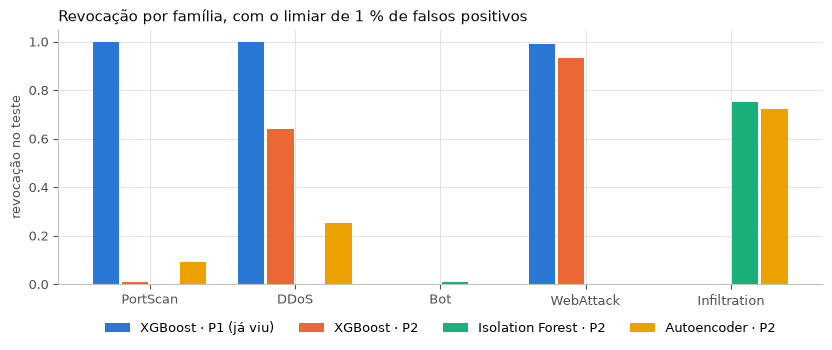

In [2]:
rows = {}
for name, label in MODELS.items():
    d = detection(name)
    rows[label] = family_recall(name) | {
        "revocação total": recall_over(name),
        "PR-AUC": d["pr_auc"],
        "FPR no teste": d["fpr"],
        "alarmes falsos": d["false_alarms"],
    }
table = pd.DataFrame(rows)
support = {f: detection("xgb_unseen")["per_family"][f]["support"] for f in TEST_FAMILIES}
table.index = [f"{i} (N={support[i]})" if i in support else i for i in table.index]
display(table.map(lambda v: f"{v:,.0f}" if v > 1 else f"{v:.3f}"))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(TEST_FAMILIES))
width = 0.2
for i, (name, label) in enumerate(MODELS.items()):
    values = list(family_recall(name).values())
    ax.bar(x + (i - 1.5) * width, values, width=width - 0.02, color=COLORS[name], label=label)
ax.set_xticks(x, TEST_FAMILIES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("revocação no teste")
ax.set_title(
    "Revocação por família, com o limiar de 1 % de falsos positivos", loc="left", color=INK
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
fig.tight_layout()
save(fig, "revocacao")
plt.show()

**Leitura.** Todos os modelos usam o mesmo orçamento de 1 % de falsos positivos na validação.

- **O supervisionado perde muito diante do desconhecido.** O XGBoost que já viu as famílias detecta
  99,0 % dos ataques. As exceções são o Infiltration, que fica fora do treino
  ([ADR 0003](../docs/adr/0003-familias-e-classes-raras.md)), e o Bot, pelo mesmo motivo da etapa 2:
  os fluxos de Bot do teste do P1 vêm depois da janela oficial do ataque. O XGBoost do P2 detecta 38,1 %. O que sobra é o que se
  parece com o treino: o DDoS (63,9 %) e os ataques web (93,3 %) saem da mesma máquina (172.16.0.1)
  para a mesma porta 80 do mesmo servidor (192.168.10.50) que os DoS de quarta.
- **Os detectores de anomalia recuperam pouco nesse ponto de operação.** O Isolation Forest detecta
  0,1 % e o autoencoder, 18,4 %, quase tudo DDoS (25,4 %) e PortScan (9,2 %). Mas são os únicos que
  pegam o Infiltration: 27 e 26 dos 36 fluxos.
- **Nenhum modelo detecta o Bot** com esse orçamento.
- **A FPR do teste passa do alvo em todos**, de 2,1 % a 8,4 %. A próxima seção mostra por quê.

## 2. Os alarmes falsos são mesmo falsos?

Na etapa 2, quase todos os falsos DDoS do XGBoost eram **fluxos de resposta**: tráfego da vítima
para o atacante, rotulado como normal. Aqui aparece um segundo caso. Na quinta à tarde, a máquina
invadida no Infiltration (192.168.10.8) varre a rede interna, e esses fluxos também estão
rotulados como normais.

In [3]:
flows = pd.read_parquet(
    ROOT / "data" / "interim" / "flows.parquet",
    columns=[schema.DAY, schema.TIMESTAMP, "source_ip", "destination_ip", schema.FAMILY],
)
attacks = flows[flows[schema.FAMILY] != schema.BENIGN]
attack_pairs = set(
    zip(
        attacks[schema.DAY].astype(str),
        attacks["source_ip"],
        attacks["destination_ip"],
        strict=True,
    )
)
infiltration = flows[flows[schema.FAMILY] == "Infiltration"]
infiltration_window = infiltration.groupby("source_ip")[schema.TIMESTAMP].agg(["min", "max"])
display(infiltration_window)


def is_response(df):
    reverse = zip(df[schema.DAY].astype(str), df["destination_ip"], df["source_ip"], strict=True)
    return np.fromiter((pair in attack_pairs for pair in reverse), bool, len(df))


def is_infiltration_scan(df):
    # Tudo o que a máquina invadida manda durante o ataque
    inside = np.zeros(len(df), bool)
    for ip, (start, end) in infiltration_window.iterrows():
        inside |= ((df["source_ip"] == ip) & df[schema.TIMESTAMP].between(start, end)).to_numpy()
    return inside


def suspicion(df):
    # Só fluxos rotulados como normais; a resposta tem precedência sobre a varredura
    benign = (df[schema.FAMILY] == schema.BENIGN).to_numpy()
    kind = np.full(len(df), "", dtype=object)
    kind[benign & is_infiltration_scan(df)] = "varredura do Infiltration"
    kind[benign & is_response(df)] = "resposta"
    return kind


test_p2 = pd.read_parquet(SPLITS / "unseen" / "test.parquet")
scan = test_p2[suspicion(test_p2) == "varredura do Infiltration"]
per_minute = scan.groupby(scan[schema.TIMESTAMP].dt.floor("min")).agg(
    fluxos=("destination_port", "size"),
    portas=("destination_port", "nunique"),
    destinos=("destination_ip", "nunique"),
)
busy = per_minute[per_minute["portas"] > 500]
print(
    f"{len(scan)} fluxos normais da máquina invadida durante o ataque; em {len(busy)} minutos ela "
    f"bate em mais de 500 portas distintas ({busy['fluxos'].sum()} fluxos, mediana de "
    f"{busy['portas'].median():.0f} portas por minuto)"
)

,min,max
source_ip,,
192.168.10.8,2017-07-06 14:19:00,2017-07-06 15:45:00


47145 fluxos normais da máquina invadida durante o ataque; em 32 minutos ela bate em mais de 500 portas distintas (42056 fluxos, mediana de 948 portas por minuto)


In [4]:
SETS = {"temporal": pd.read_parquet(SPLITS / "temporal" / "test.parquet"), "unseen": test_p2}
SUSPICION = {protocol: suspicion(df) for protocol, df in SETS.items()}
SCORES, THRESHOLDS = {}, {}
rows = {}
for name, label in MODELS.items():
    model = load_model(ROOT / "models" / name)
    protocol = RESULTS[name]["protocol"]
    df, kind = SETS[protocol], SUSPICION[protocol]
    SCORES[name] = model.score(df)
    THRESHOLDS[name] = model.metadata["threshold"]
    alarm = SCORES[name] > THRESHOLDS[name]
    benign = (df[schema.FAMILY] == schema.BENIGN).to_numpy()
    clean = benign & (kind == "")
    false_alarms = alarm & benign
    rows[label] = {
        "alarmes falsos": false_alarms.sum(),
        "em respostas": (false_alarms & (kind == "resposta")).sum(),
        "na varredura": (false_alarms & (kind == "varredura do Infiltration")).sum(),
        "FPR oficial": false_alarms.sum() / benign.sum(),
        "FPR sem os suspeitos": (alarm & clean).sum() / clean.sum(),
    }
    for day in ("thursday", "friday"):
        on_day = clean & (df[schema.DAY] == day).to_numpy()
        rows[label][f"FPR sem os suspeitos, {day}"] = (alarm & on_day).sum() / on_day.sum()
table = pd.DataFrame(rows)
display(table.map(lambda v: f"{v:,.0f}" if v > 1 else f"{v:.4f}"))

,XGBoost · P1 (já viu),XGBoost · P2,Isolation Forest · P2,Autoencoder · P2
alarmes falsos,"16,117","15,817","28,370","64,272"
em respostas,"14,166","8,748","20,304","26,442"
na varredura,"1,766",148,586,"31,072"
FPR oficial,0.0389,0.0207,0.0371,0.0841
FPR sem os suspeitos,0.0005,0.0101,0.0110,0.0099
"FPR sem os suspeitos, thursday",0.0007,0.0109,0.0101,0.0097
"FPR sem os suspeitos, friday",0.0006,0.0093,0.0119,0.0101


**Leitura.** A máquina invadida manda 47.145 fluxos rotulados como normais durante o ataque. Em 32
desses minutos, ela bate em mais de 500 portas distintas por minuto (mediana de 948): é uma
varredura de portas da rede interna, que o conjunto não rotula como ataque. Somada aos fluxos de
resposta, ela explica quase todo o excesso de alarmes:

- No autoencoder, 57.514 dos 64.272 alarmes falsos (89 %) são respostas ou varredura. Ele reconhece
  31.072 dos 47.145 fluxos da varredura, um ataque que os rótulos não contam.
- No Isolation Forest, são 20.890 dos 28.370 (74 %); no XGBoost do P2, 8.896 dos 15.817 (56 %).
- Sem esses fluxos, a FPR dos três modelos do P2 fica entre 0,99 % e 1,10 %, tanto na quinta quanto
  na sexta. O limiar escolhido com o tráfego de segunda a quarta vale nos outros dois dias.
- O XGBoost do P1 é um caso à parte. A varredura cai também na validação do P1 (3.927 dos 4.145
  alarmes da validação vêm dela), então o 1 % da validação é gasto com ela, e a FPR nos normais
  restantes do teste fica em 0,05 %.

Pelo [ADR 0001](../docs/adr/0001-versao-do-conjunto.md), os rótulos não mudam: a tabela da seção 1
fica com os rótulos oficiais, e esta seção mostra quanto do erro é da rotulagem.

## 3. Por que os detectores de anomalia perdem tanto

A revocação no ponto de operação mostra um único limiar. O ROC-AUC por família mede outra coisa:
a chance de um fluxo de ataque ter score maior que um fluxo normal sorteado. Daqui em diante, os
normais suspeitos da seção 2 ficam de fora.

,XGBoost · P1 (já viu),XGBoost · P2,Isolation Forest · P2,Autoencoder · P2
PortScan,1.000,0.762,0.816,0.986
DDoS,1.000,0.947,0.901,0.964
Bot,0.923,0.762,0.685,0.643
WebAttack,1.000,0.996,0.850,0.806
Infiltration,0.718,0.831,0.959,0.961


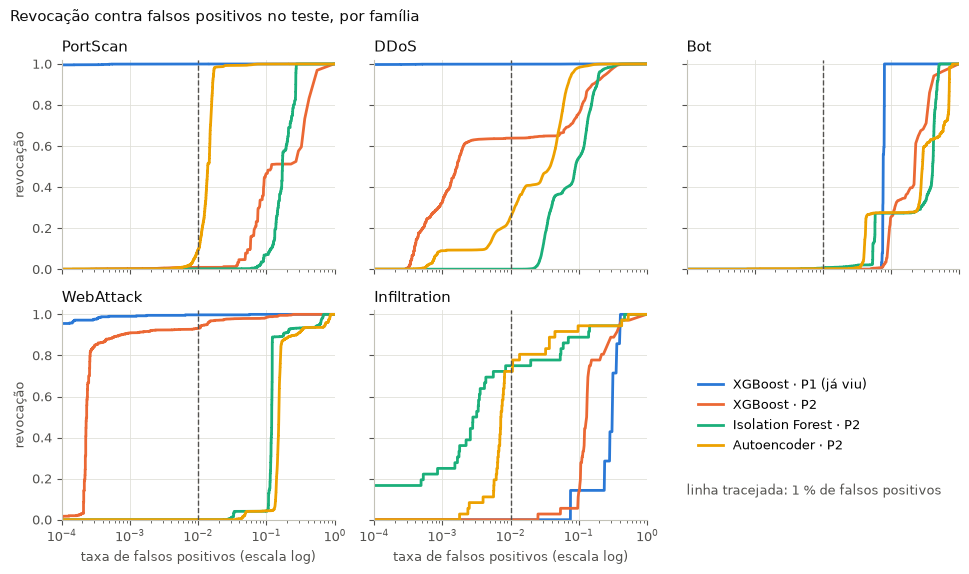

In [5]:
def family_scores(name, family):
    protocol = RESULTS[name]["protocol"]
    df, kind = SETS[protocol], SUSPICION[protocol]
    fam = df[schema.FAMILY].astype(str).to_numpy()
    keep = (fam == family) | ((fam == schema.BENIGN) & (kind == ""))
    return fam[keep] == family, SCORES[name][keep]


auc = pd.DataFrame(
    {
        label: {f: roc_auc_score(*family_scores(name, f)) for f in TEST_FAMILIES}
        for name, label in MODELS.items()
    }
)
display(auc.round(3))

fig, axes = plt.subplots(2, 3, figsize=(10, 5.8), sharex=True, sharey=True)
for ax, family in zip(axes.flat, TEST_FAMILIES, strict=False):
    for name, label in MODELS.items():
        fpr, tpr, _ = roc_curve(*family_scores(name, family))
        ax.plot(fpr, tpr, color=COLORS[name], linewidth=2, label=label)
    ax.axvline(0.01, color=MUTED, linewidth=1, linestyle="--")
    ax.set_xscale("log")
    ax.set_xlim(1e-4, 1)
    ax.set_ylim(0, 1.02)
    ax.set_title(family, loc="left", color=INK)
for ax in axes[:, 0]:
    ax.set_ylabel("revocação")
for ax in axes[1, :]:
    ax.set_xlabel("taxa de falsos positivos (escala log)")
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center left")
axes.flat[-1].text(
    0,
    0.12,
    "linha tracejada: 1 % de falsos positivos",
    color=MUTED,
    transform=axes.flat[-1].transAxes,
)
fig.suptitle(
    "Revocação contra falsos positivos no teste, por família", x=0.01, ha="left", color=INK
)
fig.tight_layout()
save(fig, "roc")
plt.show()

**Leitura.** Os detectores de anomalia ordenam bem a maioria dos ataques. O ROC-AUC do autoencoder é
de 0,986 no PortScan, 0,964 no DDoS e 0,961 no Infiltration; o do Isolation Forest, de 0,82 a 0,96
nas mesmas famílias. O problema é o ponto de operação: os ataques ficam logo atrás da cauda de 1 %
dos normais. No PortScan, a curva do autoencoder salta de cerca de 10 % para quase 100 % logo depois
da linha tracejada. Bot e ataques web exigem bem mais: o autoencoder pega 27 % do Bot com 5 % de
FPR e só 4 % dos ataques web mesmo com 10 %. Nos atributos de fluxo, eles se parecem com o tráfego
web comum.

Quanto a revocação muda se o orçamento de alarmes falsos for outro? A tabela lê a curva do teste
em quatro pontos, com as cinco famílias juntas. É só uma análise de sensibilidade: o limiar
continua o da validação, que não tem nenhum desses ataques para orientar outra escolha.

In [6]:
def all_attack_scores(name):
    protocol = RESULTS[name]["protocol"]
    df, kind = SETS[protocol], SUSPICION[protocol]
    fam = df[schema.FAMILY].astype(str).to_numpy()
    attack = np.isin(fam, TEST_FAMILIES)
    keep = attack | ((fam == schema.BENIGN) & (kind == ""))
    return attack[keep], SCORES[name][keep]


rows = {}
for name, label in MODELS.items():
    fpr, tpr, _ = roc_curve(*all_attack_scores(name))
    rows[label] = {
        f"FPR de {x:.0%}": tpr[np.searchsorted(fpr, x, side="right") - 1]
        for x in (0.01, 0.02, 0.05, 0.1)
    }
display(pd.DataFrame(rows).T.round(3))

,FPR de 1%,FPR de 2%,FPR de 5%,FPR de 10%
XGBoost · P1 (já viu),0.990,0.990,0.991,1.000
XGBoost · P2,0.381,0.383,0.416,0.634
Isolation Forest · P2,0.001,0.003,0.212,0.344
Autoencoder · P2,0.187,0.636,0.790,0.974


**Leitura.** Dobrar o orçamento de alarmes falsos quase não muda o XGBoost do P2 (de 38,1 % para
38,3 %), mas leva o autoencoder de 18,7 % para 63,6 %, à frente de todos os modelos que não viram os
ataques. Com 10 %, ele chega a 97,4 %. Isso não autoriza trocar o limiar: a validação não tem
PortScan nem DDoS, então não havia como saber de antemão que o degrau estava ali. O que a tabela
mostra é que o resultado do autoencoder depende de um limiar escolhido às cegas.

## 4. Classificador e detector juntos

A API prevista na arquitetura combina os dois modelos: o fluxo é ataque se o classificador diz que
é, e suspeito se o classificador diz que é normal, mas o detector de anomalia dispara. Aqui, a união
dos alarmes do XGBoost e do autoencoder do P2, cada um com o seu limiar.

In [7]:
kind = SUSPICION["unseen"]
fam = test_p2[schema.FAMILY].astype(str).to_numpy()
clean = (fam == schema.BENIGN) & (kind == "")
attack = np.isin(fam, TEST_FAMILIES)
alarms = {MODELS[name]: SCORES[name] > THRESHOLDS[name] for name in ("xgb_unseen", "ae_unseen")}
alarms["XGBoost + autoencoder"] = alarms[MODELS["xgb_unseen"]] | alarms[MODELS["ae_unseen"]]
rows = {
    label: {f: alarm[fam == f].mean() for f in TEST_FAMILIES}
    | {
        "revocação total": alarm[attack].mean(),
        "FPR sem os suspeitos": alarm[clean].mean(),
        "alarmes falsos sem os suspeitos": alarm[clean].sum(),
    }
    for label, alarm in alarms.items()
}
display(pd.DataFrame(rows).map(lambda v: f"{v:,.0f}" if v > 1 else f"{v:.3f}"))

,XGBoost · P2,Autoencoder · P2,XGBoost + autoencoder
PortScan,0.010,0.092,0.100
DDoS,0.639,0.254,0.703
Bot,0.000,0.003,0.003
WebAttack,0.933,0.000,0.933
Infiltration,0.000,0.722,0.722
revocação total,0.381,0.184,0.454
FPR sem os suspeitos,0.010,0.010,0.019
alarmes falsos sem os suspeitos,"6,921","6,758","13,241"


**Leitura.** A união soma o que cada modelo faz melhor: o XGBoost pega os ataques web e o DDoS, e o
autoencoder pega o Infiltration e parte do PortScan. A revocação total sobe de 38,1 % para 45,4 %,
com FPR de 1,9 % nos normais sem os suspeitos. São 13.241 alarmes falsos em dois dias, cerca de
6.600 por dia, contra uns 3.400 por dia de cada modelo sozinho.

## 5. Sem os atributos de TCP

Na etapa 2, a janela TCP inicial e o tamanho mínimo de segmento sustentavam o reconhecimento de
ataques web, força bruta e Bot, e a suspeita é que identificam a máquina, não o ataque. Aqui o
mesmo teste é feito nos três modelos do P2.

In [8]:
rows = {}
for name in ("xgb_unseen", "iforest_unseen", "ae_unseen"):
    for suffix, variant in [("", "com"), ("_sem_tcp", "sem")]:
        run = name + suffix
        d = detection(run)
        rows[(MODELS[name], variant)] = family_recall(run) | {
            "revocação total": recall_over(run),
            "PR-AUC": d["pr_auc"],
            "FPR no teste": d["fpr"],
        }
display(pd.DataFrame(rows).round(3))

XGBoost · P2        Isolation Forest · P2        Autoencoder · P2       
                         com    sem                   com    sem              com    sem
PortScan               0.010  0.001                 0.003  0.003            0.092  0.121
DDoS                   0.639  0.635                 0.000  0.004            0.254  0.313
Bot                    0.000  0.000                 0.008  0.004            0.003  0.003
WebAttack              0.933  0.842                 0.000  0.000            0.000  0.000
Infiltration           0.000  0.000                 0.750  0.694            0.722  0.500
revocação total        0.381  0.374                 0.001  0.004            0.184  0.229
PR-AUC                 0.699  0.691                 0.410  0.415            0.540  0.538
FPR no teste           0.021  0.008                 0.037  0.039            0.084  0.055

**Leitura.** Na detecção de ataques novos, os atributos de TCP não sustentam o resultado:

- **XGBoost do P2:** perde 0,7 ponto de revocação total, com os ataques web caindo de 93,3 % para
  84,2 %, e a FPR oficial cai de 2,1 % para 0,8 %.
- **Isolation Forest:** praticamente não muda.
- **Autoencoder:** sobe de 18,4 % para 22,9 %, e a FPR oficial cai de 8,4 % para 5,5 %. Em
  compensação, o Infiltration cai de 26 para 18 dos 36 fluxos.

Na etapa 2, esses atributos sustentavam o reconhecimento de famílias conhecidas. Aqui, o que detecta
o desconhecido é o comportamento do fluxo.

## 6. Conclusões

1. **O supervisionado perde 61 pontos de revocação diante do desconhecido:** de 99,0 % (P1, famílias
   conhecidas) para 38,1 % (P2), com o mesmo orçamento de 1 % de falsos positivos. O que ele ainda
   detecta são ataques parecidos com os do treino, contra o mesmo servidor.
2. **Os detectores de anomalia recuperam pouco nesse ponto de operação** (Isolation Forest 0,1 %,
   autoencoder 18,4 %), mas são os únicos que pegam o Infiltration, o ataque mais diferente do
   treino.
3. **O autoencoder ordena bem os ataques** (ROC-AUC de 0,96 a 0,99 em PortScan, DDoS e
   Infiltration) e chegaria a 63,6 % com 2 % de FPR. O resultado depende de um limiar que não dá
   para ajustar sem exemplos do ataque.
4. **Boa parte dos "alarmes falsos" são ataques que os rótulos não contam:** as respostas da vítima
   e a varredura interna da máquina invadida. Sem eles, o limiar da validação vale no teste, com FPR
   de cerca de 1 % nos dois dias.
5. **Classificador e detector se complementam:** juntos, detectam 45,4 % com 1,9 % de FPR. É o
   veredito combinado previsto para a API.
6. **Os atributos de TCP não fazem diferença para detectar ataques novos.**
7. **Nenhum modelo detecta o Bot** com esse orçamento.

Próximo passo (etapa 4): servir por uma API o XGBoost do P1, que conhece todas as famílias, e o
autoencoder, o melhor dos dois detectores de anomalia.